# Weekend Assignment 03: Customer Churn Prediction
**Internship – Week 3**

In this project, I use the Telco Customer Churn dataset to train a neural network that predicts whether a customer may leave the company. I have kept the steps simple so I can understand and explain each part.

**How to run:** Open this notebook in Google Colab. Upload `WA_Fn-UseC_-Telco-Customer-Churn.csv` when the upload cell asks for it. The notebook saves the best model as `best_churn_model.keras`.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

np.random.seed(42)
tf.random.set_seed(42)

## 2. Load and explore the data

In [2]:
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilli

In [3]:
# TotalCharges was saved as text, so I convert it to numbers.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

# Fill these few blank values with the median.
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("\nChurn counts:")
print(df["Churn"].value_counts())
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Blank TotalCharges after conversion: 11

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


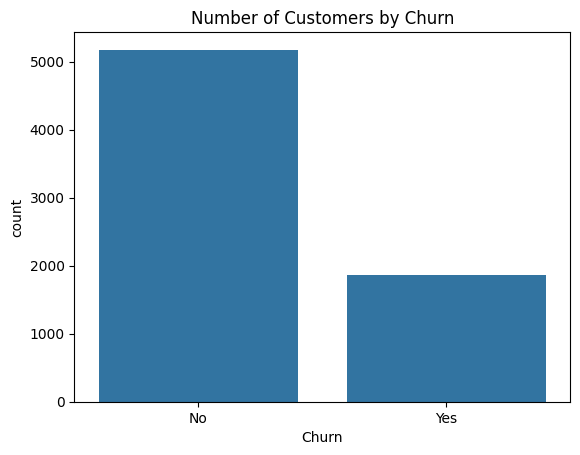

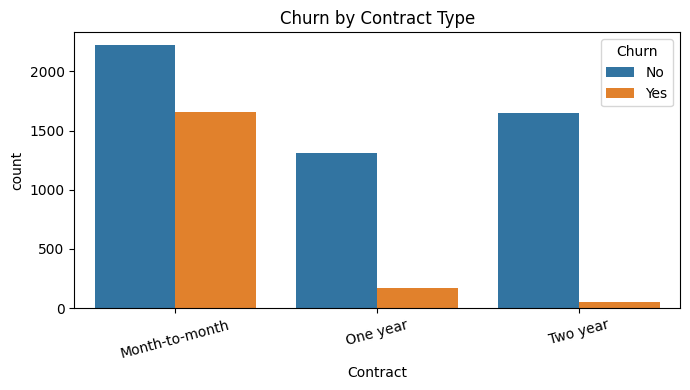

In [4]:
sns.countplot(data=df, x="Churn")
plt.title("Number of Customers by Churn")
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observation:** The two churn classes are not equal in size. There are more customers who stayed than customers who left. Contract type is also useful to inspect because churn may differ between contract groups.

## 3. Prepare the data for the neural network

In [5]:
# CustomerID is an identifier, so I do not use it as a model feature.
df = df.drop(columns=["customerID"])

# Convert the target into 0 and 1: No = 0, Yes = 1.
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])

# One-hot encoding changes text categories into numeric columns.
# I use it for categories such as Contract and PaymentMethod because they do not have a natural numeric order.
X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit the scaler only on training data to avoid using test-set information.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training rows: 5634
Testing rows: 1409
Number of input features: 30


## 4. Build and train a baseline model

In [6]:
baseline_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    verbose=1
)

baseline_loss, baseline_accuracy = baseline_model.evaluate(X_test, y_test, verbose=0)
print("Baseline test accuracy:", round(baseline_accuracy, 4))

Epoch 1/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7562 - loss: 0.4965 - val_accuracy: 0.7817 - val_loss: 0.4548
Epoch 2/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8012 - loss: 0.4280 - val_accuracy: 0.7826 - val_loss: 0.4478
Epoch 3/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8050 - loss: 0.4168 - val_accuracy: 0.7808 - val_loss: 0.4453
Epoch 4/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8076 - loss: 0.4114 - val_accuracy: 0.7826 - val_loss: 0.4447
Epoch 5/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8096 - loss: 0.4077 - val_accuracy: 0.7862 - val_loss: 0.4446
Epoch 6/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8099 - loss: 0.4049 - val_accuracy: 0.7879 - val_loss: 0.4437
Epoch 7/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8125 - loss: 0.4026 - val_accuracy: 0.7915 - val_loss: 0.4438
Epoch 8/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8134 - loss: 0.4005 - val_accuracy: 0.

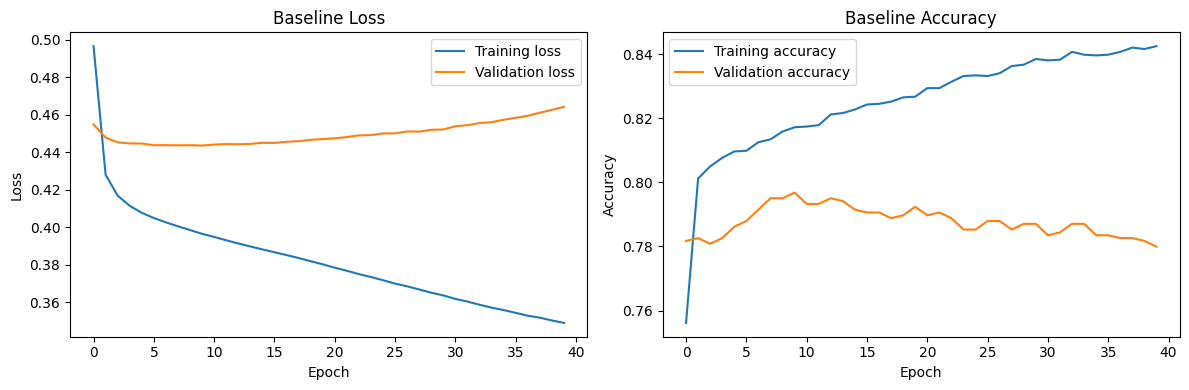

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history["loss"], label="Training loss")
plt.plot(baseline_history.history["val_loss"], label="Validation loss")
plt.title("Baseline Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(baseline_history.history["accuracy"], label="Training accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation accuracy")
plt.title("Baseline Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Tune the model

For tuning, I add Dropout and Batch Normalization. I also use Early Stopping so training can stop when validation loss does not improve. These changes may help reduce overfitting.

In [8]:
tuned_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

tuned_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

tuned_history = tuned_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

tuned_loss, tuned_accuracy = tuned_model.evaluate(X_test, y_test, verbose=0)
print("Baseline test accuracy:", round(baseline_accuracy, 4))
print("Tuned test accuracy:", round(tuned_accuracy, 4))

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6958 - loss: 0.6981 - val_accuracy: 0.7737 - val_loss: 0.5644
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7777 - loss: 0.5590 - val_accuracy: 0.7799 - val_loss: 0.5342
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7848 - loss: 0.5252 - val_accuracy: 0.7826 - val_loss: 0.5228
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7930 - loss: 0.5157 - val_accuracy: 0.7906 - val_loss: 0.5165
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7939 - loss: 0.5014 - val_accuracy: 0.7924 - val_loss: 0.5153
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7965 - loss: 0.4945 - val_accuracy: 0.7968 - val_loss: 0.5065
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8045 - loss: 0.4895 - val_accuracy: 0.7888 - val_loss: 0.5029
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7996 - loss: 0.4833 - val_accuracy: 0.

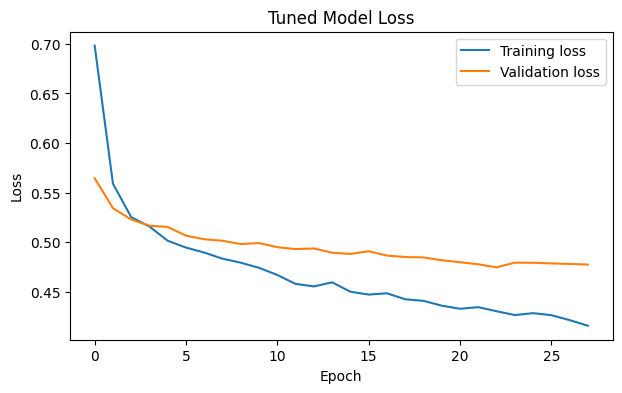

,Model,Test accuracy
0,Baseline,0.787083
1,Tuned,0.792051


In [9]:
plt.figure(figsize=(7, 4))
plt.plot(tuned_history.history["loss"], label="Training loss")
plt.plot(tuned_history.history["val_loss"], label="Validation loss")
plt.title("Tuned Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

comparison = pd.DataFrame({
    "Model": ["Baseline", "Tuned"],
    "Test accuracy": [baseline_accuracy, tuned_accuracy]
})
display(comparison)

## 6. Evaluate the tuned model

              precision    recall  f1-score   support

    No Churn       0.84      0.88      0.86      1035
       Churn       0.62      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



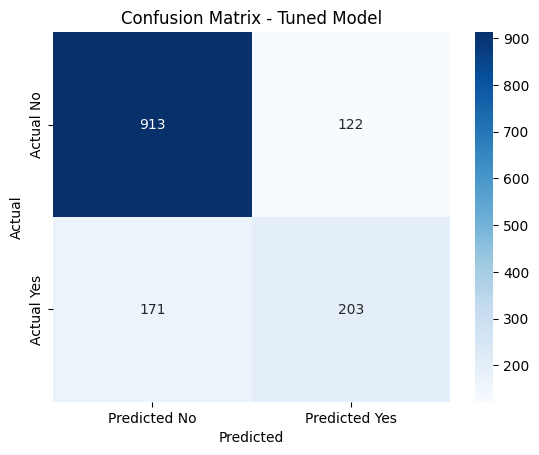

In [10]:
# Predict probabilities and convert them to class labels using 0.5 as the threshold.
y_probability = tuned_model.predict(X_test, verbose=0).ravel()
y_pred = (y_probability >= 0.5).astype(int)

print(classification_report(
    y_test, y_pred, target_names=["No Churn", "Churn"], zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix - Tuned Model")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

**Why accuracy is not enough:** The dataset has more customers who did not churn than customers who did. A model can get a reasonable accuracy while still missing customers who actually leave, so precision, recall, F1-score and the confusion matrix give a fuller picture.

## 7. Save the model and predict for a hypothetical customer

In [11]:
# Save the tuned model in Keras format.
tuned_model.save("best_churn_model.keras")
print("Saved best_churn_model.keras")

# This example uses the first test customer as a template, then gives it a new hypothetical prediction.
# Features must be in the same order and use the same scaling as the training data.
loaded_model = keras.models.load_model("best_churn_model.keras")

example_customer = X_test[0].reshape(1, -1)
probability = float(loaded_model.predict(example_customer, verbose=0)[0][0])
prediction = "Likely to churn" if probability >= 0.5 else "Likely to stay"

print("Predicted result:", prediction)
print("Estimated churn probability:", round(probability, 3))

# Download the model file from Colab.
files.download("best_churn_model.keras")

Saved best_churn_model.keras
Predicted result: Likely to stay
Estimated churn probability: 0.059


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Short answer: CNN vs. RNN

I would use a CNN when the data has patterns that are close to each other, such as pixels in an image. For example, a CNN can help classify cats and dogs from photos. I would use an RNN for sequential data where earlier items can affect later items, such as text or time-series data. For example, an RNN can be used to predict the next word in a sentence.